# Testing del Clasificador de Palabras Clave
Este notebook evalúa el rendimiento del algoritmo importando directamente la clase desde `classifier.py` y leyendo las reglas desde `config.json`.

In [21]:
import pandas as pd
# Importamos la clase directamente desde tu archivo local
from keyword_classifier import KeywordClassifier

In [22]:
# 1. Instanciar el clasificador usando el config.json de la raíz
clasificador = KeywordClassifier.from_json("config.json")
print("Clasificador inicializado correctamente desde config.json.")

Clasificador inicializado correctamente desde config.json.


In [23]:
# 2.Dataset de prueba con la Verdad Fundamental (Ground Truth)
# Cargar el dataset
df = pd.read_csv("dataset_pruebas.csv")

# Ver una muestra
display(df.head())

,id_ticket,texto,categoria_real
0,TKT-00001,Quiero comprar el plan anual.,Ventas y Comercial
1,TKT-00002,¿A QUÉ HORA ABREN?,Sin clasificación
2,TKT-00003,Necesito una copia de mi contrato.,Recursos Humanos
3,TKT-00004,¿A qué hora abren?,Sin clasificación
4,TKT-00005,"Llevo esperando tres meses, un asco de empresa.",Reclamos


¿Qué contiene este Dataset?
1. 10.000 filas con las columnas: id_ticket, texto, y categoria_real.
2. Trampas (Falsos Negativos): el archivo posee falsos negativos

In [24]:
# 3. Aplicar el clasificador al DataFrame
def aplicar_clasificador(texto):
    res = clasificador.classify_text(texto)
    return pd.Series([res['categoria'], res['keyword_match']])

df[['categoria_predicha', 'evidencia_keyword']] = df['texto'].apply(aplicar_clasificador)
display(df)

,id_ticket,texto,categoria_real,categoria_predicha,evidencia_keyword
0,TKT-00001,Quiero comprar el plan anual.,Ventas y Comercial,Ventas y Comercial,comprar
1,TKT-00002,¿A QUÉ HORA ABREN?,Sin clasificación,Sin clasificación,None
2,TKT-00003,Necesito una copia de mi contrato.,Recursos Humanos,Recursos Humanos,contrato
3,TKT-00004,¿A qué hora abren?,Sin clasificación,Sin clasificación,None
4,TKT-00005,"Llevo esperando tres meses, un asco de empresa.",Reclamos,Reclamos,esperando
...,...,...,...,...,...
9995,TKT-09996,hay mucha lentitud en la red.,Soporte TI,Soporte TI,lentitud
9996,TKT-09997,quiero pedir mis vacaciones para febrero.,Recursos Humanos,Recursos Humanos,vacaciones
9997,TKT-09998,mi tarjeta fue rechazada.,Facturación y Pagos,Facturación y Pagos,tarjeta
9998,TKT-09999,El internet está malo en la oficina.,Soporte TI,Soporte TI,internet


Precisión Global (Accuracy): 97.42%

--- REPORTE DE MÉTRICAS ---
                     precision    recall  f1-score   support

Facturación y Pagos       0.87      1.00      0.93      1696
           Reclamos       1.00      1.00      1.00      1664
   Recursos Humanos       1.00      0.84      0.91      1580
  Sin clasificación       1.00      1.00      1.00      1690
         Soporte TI       1.00      1.00      1.00      1673
 Ventas y Comercial       1.00      1.00      1.00      1697

           accuracy                           0.97     10000
          macro avg       0.98      0.97      0.97     10000
       weighted avg       0.98      0.97      0.97     10000



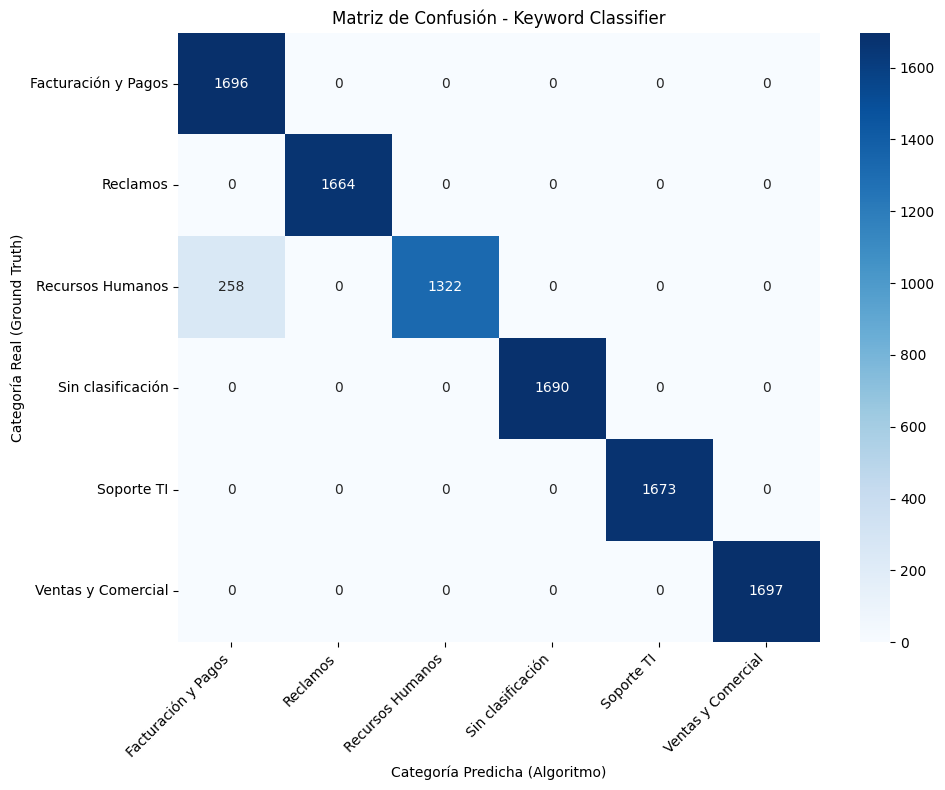


--- CASOS FALLIDOS (Falsos Negativos para revisar en el JSON) ---


,texto,categoria_real,categoria_predicha
12,TENGO DUDAS CON EL PAGO DE MI SUELDO.,Recursos Humanos,Facturación y Pagos
39,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
44,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
114,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
173,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
188,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
213,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
261,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
311,Tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos
403,tengo dudas con el pago de mi sueldo.,Recursos Humanos,Facturación y Pagos


In [25]:
# 4. Evaluar el rendimiento (Métricas y Matriz de Confusión)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Calcular aciertos básicos
df['acierto'] = df['categoria_real'] == df['categoria_predicha']
accuracy = df['acierto'].mean()
print(f"Precisión Global (Accuracy): {accuracy * 100:.2f}%\n")

# 1. Reporte de Clasificación (Precision, Recall, F1-Score)
print("--- REPORTE DE MÉTRICAS ---")
print(classification_report(df['categoria_real'], df['categoria_predicha']))

# 2. Generar y Mostrar Matriz de Confusión
labels = sorted(df['categoria_real'].unique())
cm = confusion_matrix(df['categoria_real'], df['categoria_predicha'], labels=labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.xlabel('Categoría Predicha (Algoritmo)')
plt.ylabel('Categoría Real (Ground Truth)')
plt.title('Matriz de Confusión - Keyword Classifier')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# 3. Filtrar y mostrar dónde falló el algoritmo
errores = df[~df['acierto']]
if not errores.empty:
    print("\n--- CASOS FALLIDOS (Falsos Negativos para revisar en el JSON) ---")
    display(errores[['texto', 'categoria_real', 'categoria_predicha']].head(15))
else:
    print("\n¡El clasificador acertó el 100% de los casos!")